In [2]:
from sklearn.preprocessing import LabelEncoder
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd

In [ ]:
labeled_data = pd.read_csv('labeled_data_3000-6000.csv')
print(labeled_data.head())

   VehicleID                                              Label  \
0     7007.0  ['Follow_behind', 'Follow_behind', 'Catch_up',...   
1     7008.0  ['Slow_down', 'Follow_behind', 'Follow_behind'...   
2     7009.0  ['Follow_behind', 'Follow_behind', 'Fall_behin...   
3     7013.0  ['Catch_up', 'Slow_down', 'Fall_behind', 'Fall...   
4     7014.0  ['Follow_behind', 'Speed_up', 'Fall_behind', '...   

                        Point  
0            [0, 45, 92, 199]  
1  [0, 50, 85, 118, 134, 199]  
2       [0, 40, 74, 119, 179]  
3            [0, 40, 65, 179]  
4            [0, 32, 61, 219]  


In [ ]:
full_data = pd.read_csv('trainHH_full_data.csv')
print(full_data.head())

   VehicleID  timestamp    x_lead   x_follow     v_lead   v_follow    a_lead  \
0          3   0.000000  0.000000 -21.618937  15.205611  15.397437 -0.125165   
1          3   0.099981  1.491581 -19.663385  15.198118  15.402246 -0.098205   
2          3   0.199914  2.995142 -18.280299  15.168826  15.379181 -0.056524   
3          3   0.299796  4.532177 -16.775873  15.174463  15.399492 -0.007223   
4          3   0.399628  6.001878 -15.287254  15.136314  15.446208  0.039555   

   a_follow   distance   delta_v  smooth_v_follow  smooth_distance  \
0  0.056585  16.618937 -0.191827        15.397437        16.618937   
1  0.101276  16.154966 -0.204129        15.398499        16.516541   
2  0.165915  16.275442 -0.210355        15.394235        16.463331   
3  0.237887  16.308050 -0.225029        15.395396        16.429061   
4  0.301572  16.289132 -0.309894        15.406610        16.398180   

   smooth_delta_v  FrameID  time_headway  
0       -0.191827        0      1.079331  
1       -0.1

In [ ]:
# Load data
labeled_data = pd.read_csv('labeled_data_3000-6000.csv')
full_data = pd.read_csv('trainHH_full_data.csv')

In [ ]:
# SAVE - pattern-based data to DataFrame, with file
import numpy as np
import pandas as pd

# Function to merge adjacent segments with the same pattern
def merge_same_pattern_segments(points, labels):
    merged_points = []
    merged_labels = []
    
    current_start = points[0]
    current_label = labels[0]

    for i in range(1, len(labels)):
        if labels[i] == current_label:  # Same pattern, continue merging
            continue
        else:
            # When the label changes, close the previous range and start a new one
            merged_points.append((current_start, points[i]))  # End at the last frame of the previous segment
            merged_labels.append(current_label)
            current_start = points[i]  # Start new range
            current_label = labels[i]  # Change to new pattern

    # Add the final pattern
    merged_points.append((current_start, points[-1]))
    merged_labels.append(current_label)

    return merged_points, merged_labels

# Function to calculate the slope of acceleration for each pattern segment and save data as DataFrame
def calculate_pattern_data_to_df(vehicle_indices, pattern_names):
    delta_v_list = []
    distance_list = []
    acceleration_list = []
    pattern_list = []
    vehicle_id_list = []
    time_headway_list = []
    avg_alead_list = []
    delta_a_list = []

    for pattern_name in pattern_names:
        for vehicle_id_index in vehicle_indices:
            vehicle_id = labeled_data.loc[vehicle_id_index, 'VehicleID']
            vehicle_data = full_data[full_data['VehicleID'] == vehicle_id]

            # Extract the points and labels for the patterns
            pattern_points = eval(labeled_data.loc[vehicle_id_index, 'Point'])
            pattern_labels = eval(labeled_data.loc[vehicle_id_index, 'Label'])

            # Merge adjacent segments with the same pattern
            merged_points, merged_labels = merge_same_pattern_segments(pattern_points, pattern_labels)

            # Filter out redundant patterns where the start and end frame are the same
            filtered_points = [(start, end) for start, end in merged_points if start != end]
            filtered_labels = [merged_labels[i] for i in range(len(merged_labels)) if merged_points[i][0] != merged_points[i][1]]

            for i in range(len(filtered_labels)):
                if filtered_labels[i].lower() == pattern_name.lower():
                    start_frame, end_frame = filtered_points[i]
                    
                    # Filter data for the current segment
                    segment_data = vehicle_data[(vehicle_data['FrameID'] >= start_frame) & (vehicle_data['FrameID'] <= end_frame)]
                    # Check if any acceleration is outside the range [-8, 8]. If so, skip this segment.
                    if any(segment_data['a_follow'] < -6) or any(segment_data['a_follow'] > 8):
                        continue  # Skip this segment
                    if pattern_name == 'speed_up':
                        if any(-segment_data['smooth_delta_v'] > 2.5) and any(segment_data['a_follow'] > 0.5):
                            continue  # Skip this segment    

                    avg_delta_v = -segment_data['smooth_delta_v'].mean()
                    avg_distance = segment_data['distance'].mean()
                    avg_acceleration = segment_data['a_follow'].mean()
                    avg_time_headway = segment_data['time_headway'].mean()
                    avg_alead = segment_data['a_lead'].mean()
                    delta_a = avg_acceleration - avg_alead
                    delta_v_list.append(avg_delta_v)
                    distance_list.append(avg_distance)
                    acceleration_list.append(avg_acceleration)
                    pattern_list.append(pattern_name)
                    vehicle_id_list.append(vehicle_id)
                    time_headway_list.append(avg_time_headway)
                    avg_alead_list.append(avg_alead)
                    delta_a_list.append(delta_a)

    # Create DataFrame from the lists
    data = {
        'VehicleID': vehicle_id_list,
        'Pattern': pattern_list,
        'Delta_v': delta_v_list,
        'Distance': distance_list,
        'Acceleration': acceleration_list,
        'time_headway': time_headway_list,
        'a_lead': avg_alead_list,
        'delta_a': delta_a_list
    }
    df = pd.DataFrame(data)
    
    # Save the DataFrame to a CSV file
    df.to_csv('avg_pattern_data.csv', index=False)

    return df


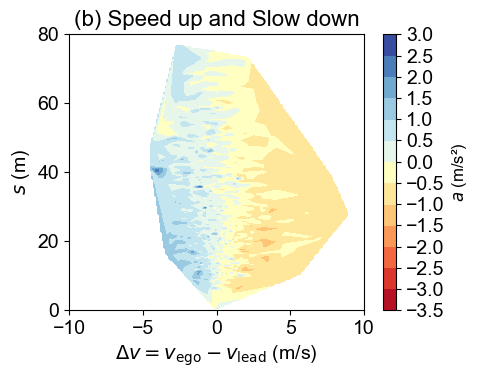

In [ ]:
# FIGURE - plot contour of speed_related patterns
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
import pandas as pd

# Load the dataset
df = pd.read_csv('avg_pattern_data.csv')
plt.rc('font', family='Arial', size=14)

# Function to plot contour map for speed-related patterns only
def plot_speed_related_pattern_contour(df, save_path=None):
    # Define speed-related patterns
    speed_patterns = ['speed_up', 'slow_down']
    
    # Calculate the global vmin and vmax based on speed-related patterns
    speed_data = df[df['Pattern'].isin(speed_patterns)]
    all_accelerations = speed_data['Acceleration'].values

    interval = 0.5  # Define the interval for colorbar ticks
    global_vmin = -3.5
    global_vmax = 3
    colorbar_ticks = np.arange(global_vmin, global_vmax + interval, interval)

    # Create a figure for speed-related patterns
    fig, ax = plt.subplots(figsize=(5, 4))

    # Extract data for speed-related patterns
    avg_delta_v_array = speed_data['Delta_v'].values
    avg_distance_array = speed_data['Distance'].values
    avg_acceleration_array = speed_data['Acceleration'].values

    # Create a grid for interpolation
    grid_delta_v, grid_distance = np.mgrid[-10:10:200j, 0:80:200j]
    grid_acceleration = griddata((avg_delta_v_array, avg_distance_array), avg_acceleration_array, (grid_delta_v, grid_distance), method='linear')

    # Plot contour for speed-related patterns
    contour_set = ax.contourf(grid_delta_v, grid_distance, grid_acceleration, cmap='RdYlBu', levels=colorbar_ticks, vmin=global_vmin, vmax=global_vmax)
    ax.set_xlabel('$\Delta v = v_{\mathrm{ego}} - v_{\mathrm{lead}}$ (m/s)', fontsize=14)
    ax.set_ylabel('$s$ (m)', fontsize=14)
    ax.set_title('(b) Speed up and Slow down', fontsize=16)

    # Add colorbar
    cbar = fig.colorbar(contour_set, ax=ax, ticks=colorbar_ticks)
    cbar.set_label('$a$ (m/s²)', fontsize=12)

    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight')

    plt.show()

# Example usage
plot_speed_related_pattern_contour(df, save_path='speedup_slowdown_contour1.pdf')
# plot_speed_related_pattern_contour(df)


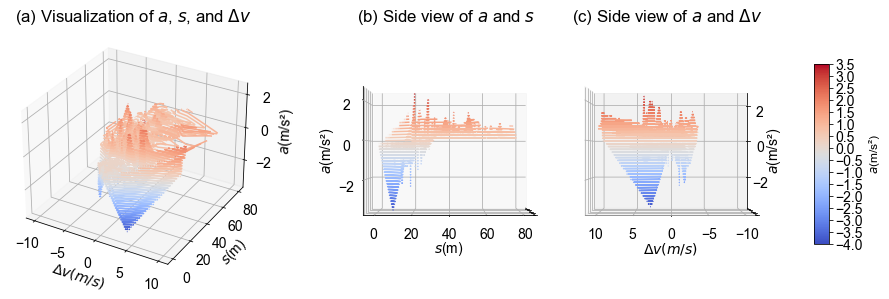

In [ ]:
# 3D contour of distance-related patterns
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import gridspec

# Function to create a 3D contour plot with consistent spacing between subplots
def plot_3d_with_side_views(df, pattern_names, save_path=None):
    # Filter data for the specified patterns
    combined_data = df[df['Pattern'].isin(pattern_names)]

    # Extract variables
    delta_v = combined_data['Delta_v'].values
    distance = combined_data['Distance'].values
    acceleration = 2 * combined_data['Acceleration'].values  # Using 'Acceleration' for Z-axis height

    # Define colorbar range based on acceleration values
    interval = 0.5
    global_vmin = np.floor(np.nanmin(acceleration) / interval) * interval
    global_vmax = np.ceil(np.nanmax(acceleration) / interval) * interval
    colorbar_ticks = np.arange(global_vmin, global_vmax + interval, interval)

    # Create a grid for delta_v and distance
    grid_delta_v, grid_distance = np.mgrid[-10:10:200j, 0:80:200j]

    # Interpolate acceleration over the grid
    grid_acceleration = griddata(
        (delta_v, distance), 
        acceleration, 
        (grid_delta_v, grid_distance), 
        method='linear'
    )

    # Create a figure and manually adjust subplot positions
    fig = plt.figure(figsize=(14, 5))

    # Main 3D contour plot (Default View)
    ax1 = fig.add_axes([0.05, 0.15, 0.25, 0.7], projection='3d')  # Adjust position and size for even spacing
    ax1.contour3D(grid_delta_v, grid_distance, grid_acceleration, 50, cmap='coolwarm')
    ax1.set_xlabel('$\Delta v(m/s)$')
    ax1.set_ylabel('$s$(m)')
    ax1.set_zlabel('$a$(m/s²)')
    ax1.set_title('(a) Visualization of $a$, $s$, and $\Delta v$')
    ax1.view_init(elev=30, azim=-60)

    # Side view from the delta_v axis
    ax2 = fig.add_axes([0.36, 0.15, 0.25, 0.7], projection='3d')  # Adjust position to ensure equal spacing
    ax2.contour3D(grid_delta_v, grid_distance, grid_acceleration, 50, cmap='coolwarm')
    ax2.set_xlabel('')  # Remove the delta_v label
    ax2.set_ylabel('$s$(m)', labelpad=10)
    ax2.set_zlabel('$a$(m/s²)')
    ax2.set_title('(b) Side view of $a$ and $s$')
    ax2.view_init(elev=0, azim=0)
    ax2.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)

    # Side view from the distance axis
    ax3 = fig.add_axes([0.58, 0.15, 0.25, 0.7], projection='3d')  # Adjust position for equal spacing
    ax3.contour3D(grid_delta_v, grid_distance, grid_acceleration, 50, cmap='coolwarm')
    ax3.set_xlabel('$\Delta v(m/s)$', labelpad=10)
    ax3.set_ylabel('')  # Remove the gap label
    ax3.set_zlabel('$a$(m/s²)')
    ax3.set_title('(c) Side view of $a$ and $\Delta v$')
    ax3.view_init(elev=0, azim=90)
    ax3.tick_params(axis='y', which='both', left=False, right=False, labelleft=False)

    # Add a smaller color bar
    cbar_ax = fig.add_axes([0.85, 0.25, 0.015, 0.5])  # Adjust position and make colorbar narrower
    mappable = plt.cm.ScalarMappable(cmap='coolwarm')
    mappable.set_array(acceleration)
    mappable.set_clim(global_vmin, global_vmax)
    cbar = fig.colorbar(mappable, cax=cbar_ax, ticks=colorbar_ticks)
    cbar.set_label('$a$(m/s²)', fontsize=12)
    # Save the figure if a save path is provided
    if save_path:
        plt.savefig(save_path, format='png', bbox_inches='tight', dpi=300)  # Save with high resolution


    plt.show()

# Example usage
patterns_to_plot = ['catch_up', 'fall_behind', 'follow_behind']

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error

# Load datasets
df = pd.read_csv('avg_pattern_data.csv')

# Define equations for different acceleration models
def model_1(data, b1, b2):  # a = b1 / s^2 + b2 * delta_v
    s, delta_v = data
    return b1 / (s**2) + b2 * delta_v

def model_2(data, b1, b2):  # a = b1 / s + b2 * sqrt(delta_v)
    s, delta_v = data
    return b1 / s + b2 * np.sqrt(abs(delta_v))

def model_3(data, b1, b2):  # a = b1 * s^2 + b2 * sqrt(delta_v)
    s, delta_v = data
    return b1 * (s**2) + b2 * np.sqrt(abs(delta_v))

# def model_4(data, b1, b2, b3, b4):  # a = b1 * s + b2 * delta_v
#     s, delta_v = data
#     return logarithmic(s, b1, b2) + b3 * delta_v + b4
def model_4(data, b1, b2, b3, b4):
    s, delta_v = data
    # Apply a threshold to avoid log of zero or negative
    s_adjusted = np.maximum(s + b2, 1e-6)
    return b1 * np.log10(s_adjusted) + b3 * delta_v + b4

# def model_5(data, b1, b2, b3, b4, b5):  # a = b1 * s + b2 * delta_v
#     s, delta_v = data
#     return cubic(s, b1, b2, b3, b4) + b5 * delta_v

# def model_6(s, b1, b2, b3, b4): 
#     s, delta_v = data             
#     return exponential(s, b1, b2, b3) + b4 * delta_v


def prepare_data(df, pattern_names):
    # Filter for specified patterns and apply constraints
    combined_data = df[df['Pattern'].isin(pattern_names)]
    combined_data = combined_data[~((combined_data['Distance'] > 30) & (combined_data['Acceleration'] < 0))]
    combined_data = combined_data[~((combined_data['Distance'] < 20) & (combined_data['Acceleration'] > 0))]
    combined_data = combined_data[~(combined_data['Distance'] < 0)]
    combined_data = combined_data[~((combined_data['Delta_v'] > 10)|(combined_data['Delta_v'] < -10))]
    combined_data = combined_data[~((5 * combined_data['Acceleration'] > 8)|(5 * combined_data['Acceleration'] < -8))]  # New filter rule
    
    # Drop any rows with NaN values in relevant columns
    combined_data = combined_data.dropna(subset=['Delta_v', 'Distance', 'Acceleration'])
    
    # Extract variables
    delta_v = combined_data['Delta_v'].values
    distance = combined_data['Distance'].values
    acceleration = combined_data['Acceleration'].values  # Adjust acceleration if needed
    
    return delta_v, distance, acceleration
# Define a function to fit models and calculate MSE for each
def fit_models(delta_v, distance, acceleration):
    models = {
        "model_1 (a = b1 / s^2 + b2 * delta_v)": model_1,
        "model_2 (a = b1 / s + b2 * sqrt(delta_v))": model_2,
        "model_3 (a = b1 * s^2 + b2 * sqrt(delta_v))": model_3,
        "model_4 (a = logarithmic(s, b1, b2) + b3 * delta_v + b4)": model_4
        # "model_5 (a = cubic(s, b1, b2, b3, b4) + b5 * delta_v)": model_5
        # "model_6 (a = exponential(s, b1, b2, b3) + b4 * delta_v + b5)": model_6
    }
    
    mse_results = {}
    best_mse = float('inf')
    best_params = None
    best_model_name = None

    # Fit each model and calculate MSE
    for model_name, model in models.items():
        try:
            params, _ = curve_fit(model, (distance, delta_v), acceleration)
            fitted_acceleration = model((distance, delta_v), *params)
            mse = mean_squared_error(acceleration, fitted_acceleration)
            mse_results[model_name] = mse
            
            # Print MSE and parameters for each model
            print(f"{model_name} parameters: {params}")
            print(f"{model_name} MSE: {mse}\n")
            
            # Update best model if MSE is lower
            if mse < best_mse:
                best_mse = mse
                best_params = params
                best_model_name = model_name
        
        except RuntimeError:
            print(f"{model_name} fitting failed.")

    # Print summary of all MSEs
    print("MSEs for all models:")
    for name, mse in mse_results.items():
        print(f"{name}: MSE = {mse}")

    print(f"\nBest model is {best_model_name} with parameters {best_params} and MSE {best_mse}")
    return best_model_name, best_params, best_mse

# Prepare data for distance-related patterns
pattern_names = ['catch_up', 'fall_behind', 'follow_behind']
delta_v, distance, acceleration = prepare_data(df, pattern_names)

# Run the model fitting
best_model_name, best_params, best_mse = fit_models(delta_v, distance, acceleration)

# Save the best fitting parameters and MSE for reference
print(f"\nOptimal model: {best_model_name}")
print(f"Optimized parameters: {best_params}")
print(f"Optimal MSE: {best_mse}")


model_1 (a = b1 / s^2 + b2 * delta_v) parameters: [-0.00345863 -0.01678827]
model_1 (a = b1 / s^2 + b2 * delta_v) MSE: 0.039209635442324815

model_2 (a = b1 / s + b2 * sqrt(delta_v)) parameters: [-0.23105813  0.04862517]
model_2 (a = b1 / s + b2 * sqrt(delta_v)) MSE: 0.03804271711287406

model_3 (a = b1 * s^2 + b2 * sqrt(delta_v)) parameters: [ 6.44387307e-05 -3.13322381e-02]
model_3 (a = b1 * s^2 + b2 * sqrt(delta_v)) MSE: 0.0351634337758009

model_4 (a = logarithmic(s, b1, b2) + b3 * delta_v + b4) parameters: [ 0.51112547  1.43167061 -0.00757974 -0.70222881]
model_4 (a = logarithmic(s, b1, b2) + b3 * delta_v + b4) MSE: 0.030724154811754407

MSEs for all models:
model_1 (a = b1 / s^2 + b2 * delta_v): MSE = 0.039209635442324815
model_2 (a = b1 / s + b2 * sqrt(delta_v)): MSE = 0.03804271711287406
model_3 (a = b1 * s^2 + b2 * sqrt(delta_v)): MSE = 0.0351634337758009
model_4 (a = logarithmic(s, b1, b2) + b3 * delta_v + b4): MSE = 0.030724154811754407

Best model is model_4 (a = logarithmi

In [ ]:
# fitting speed_related patterns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error

# Load datasets
labeled_data = pd.read_csv('labeled_data_3000-6000.csv')
full_data = pd.read_csv('trainHH_full_data.csv')
plt.rc('font', family='Arial', size=14)
# Define the acceleration model function
def acceleration_model(data, b1, b2):
    delta_v, distance = data
    distance = np.clip(distance, 1e-6, None)  # Ensure positive non-zero distances
    return (b1 / np.sqrt(distance) + b2) * delta_v

# Calculate average acceleration for each pattern segment across multiple patterns
def calculate_acceleration_slope_patterns(vehicle_indices, pattern_names):
    delta_v_list = []
    distance_list = []
    acceleration_list = []

    for vehicle_id_index in vehicle_indices:
        vehicle_id = labeled_data.loc[vehicle_id_index, 'VehicleID']
        vehicle_data = full_data[full_data['VehicleID'] == vehicle_id]

        pattern_points = eval(labeled_data.loc[vehicle_id_index, 'Point'])
        pattern_labels = eval(labeled_data.loc[vehicle_id_index, 'Label'])

        merged_points, merged_labels = merge_same_pattern_segments(pattern_points, pattern_labels)

        # Filter out redundant patterns
        filtered_points = [(start, end) for start, end in merged_points if start != end]
        filtered_labels = [merged_labels[i] for i in range(len(merged_labels)) if merged_points[i][0] != merged_points[i][1]]

        for i in range(len(filtered_labels)):
            if filtered_labels[i].lower() in [pattern.lower() for pattern in pattern_names]:
                start_frame, end_frame = filtered_points[i]
                
                segment_data = vehicle_data[(vehicle_data['FrameID'] >= start_frame) & (vehicle_data['FrameID'] <= end_frame)]

                if any(segment_data['a_follow'] < -6) or any(segment_data['a_follow'] > 8):
                    continue  # Skip segment with extreme accelerations

                avg_delta_v = segment_data['smooth_delta_v'].mean()
                avg_distance = segment_data['smooth_distance'].mean()
                avg_acceleration = segment_data['a_follow'].mean()

                if avg_distance > 0:
                    delta_v_list.append(avg_delta_v)
                    distance_list.append(avg_distance)
                    acceleration_list.append(avg_acceleration)

    return np.array(delta_v_list), np.array(distance_list), np.array(acceleration_list)

# Optimize b1 and b2 for combined speed-related patterns and calculate MSE
def optimize_parameters_for_patterns(vehicle_indices, pattern_names):
    delta_v_array, distance_array, acceleration_array = calculate_acceleration_slope_patterns(vehicle_indices, pattern_names)

    if delta_v_array.size < 2 or distance_array.size < 2 or acceleration_array.size < 2:
        print(f"Insufficient data for patterns '{pattern_names}' for optimization.")
        return None, None, None

    delta_v_flat = delta_v_array.flatten()
    distance_flat = distance_array.flatten()
    acceleration_flat = acceleration_array.flatten()
    
    params, _ = curve_fit(
        lambda data, b1, b2: acceleration_model((data[0], data[1]), b1, b2), 
        (delta_v_flat, distance_flat), acceleration_flat
    )
    
    b1_opt, b2_opt = params

    # Calculate fitted acceleration and MSE
    fitted_acceleration = acceleration_model((delta_v_flat, distance_flat), b1_opt, b2_opt)
    mse = mean_squared_error(acceleration_flat, fitted_acceleration)

    return b1_opt, b2_opt, mse

# Plot the fitted model as a contour map and save the figure
def plot_fitted_contour(b1_opt, b2_opt, save_path=None):
    grid_delta_v, grid_distance = np.meshgrid(np.linspace(-10, 10, 100), np.linspace(1, 80, 100))
    grid_acceleration = acceleration_model((grid_delta_v, grid_distance), b1_opt, b2_opt)
    
    plt.figure(figsize=(5, 4))
    contour_set = plt.contourf(grid_delta_v, grid_distance, grid_acceleration, cmap='RdYlBu', levels=np.linspace(-8, 8, 20))
    
    colorbar = plt.colorbar(contour_set)
    colorbar.set_label('$a$ (m/s²)', fontsize=14)  # Correct way to set font size for colorbar label
    plt.title('(c) Multivariate regression analysis', fontsize=16)
    plt.xlabel('$\Delta v = v_{\mathrm{ego}} - v_{\mathrm{lead}}$ (m/s)', fontsize=14)
    plt.ylabel('$s$ (m)', fontsize=14)
    plt.axvline(x=0, color='black', linestyle='--', linewidth=1)  # Add a line at delta_v = 0
    
    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight', dpi=300)  # Save with high resolution

    plt.show()

# Specify vehicle indices and speed-related patterns
vehicle_indices = range(len(labeled_data))  # Adjust as needed
speed_patterns = ['speed_up', 'slow_down']

# Run the optimization for speed-related patterns
b1_opt, b2_opt, mse = optimize_parameters_for_patterns(vehicle_indices, speed_patterns)

# Print and visualize the optimized parameters and MSE if available
if b1_opt is not None and b2_opt is not None:
    print("Optimized b1:", b1_opt)
    print("Optimized b2:", b2_opt)
    print("Mean Squared Error (MSE):", mse)
    plot_fitted_contour(b1_opt, b2_opt, save_path='speed_patterns_fitting.pdf')
    # plot_fitted_contour(b1_opt, b2_opt)
else:
    print("Optimization could not be completed due to insufficient data.")

Pattern transition probability matrix.

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
#set font
plt.rcParams['font.family'] = 'Arial'
# Define your transition probabilities
transitions = {
    "FollowBehind": {"FollowBehind": 0.3902, "CatchUp": 0.1313, "FallBehind": 0.1560, "SpeedUp": 0.1207, "SlowDown": 0.0899, "HoldSpeed": 0.1119},
    "CatchUp": {"SlowDown": 0.2578, "FallBehind": 0.1383, "HoldSpeed": 0.1060, "SpeedUp": 0.1152, "FollowBehind": 0.2572, "CatchUp": 0.1255},
    "SlowDown": {"FollowBehind": 0.2148, "FallBehind": 0.1785, "HoldSpeed": 0.0970, "SlowDown": 0.0704, "SpeedUp": 0.3119, "CatchUp": 0.1274},
    "FallBehind": {"FollowBehind": 0.2945, "HoldSpeed": 0.1137, "SpeedUp": 0.2623, "CatchUp": 0.1170, "SlowDown": 0.0644, "FallBehind": 0.1481},
    "SpeedUp": {"FallBehind": 0.1861, "SpeedUp": 0.1481, "FollowBehind": 0.2622, "SlowDown": 0.1324, "CatchUp": 0.1927, "HoldSpeed": 0.0786},
    "HoldSpeed": {"SlowDown": 0.0884, "FollowBehind": 0.2911, "FallBehind": 0.1337, "HoldSpeed": 0.2514, "CatchUp": 0.1337, "SpeedUp": 0.1017}
}

# Create a directed graph
G = nx.DiGraph()

# Add nodes and edges
for state, edges in transitions.items():
    G.add_node(state)
    for dest_state, prob in edges.items():
        G.add_edge(state, dest_state, weight=prob, label=f"{prob:.2f}")

# Configure the plot's figure size
plt.figure(figsize=(10, 7))

# Position nodes using a layout
pos = nx.spring_layout(G, seed=42)  # Seed for reproducible layout

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_color='dodgerblue', node_size=2000, alpha=0.8)

# Draw edges with varying width based on probability
edges = G.edges(data=True)
edge_colors = [data['weight'] for _, _, data in edges]

nx.draw_networkx_edges(G, pos, arrowstyle='-|>', arrowsize=20,  edge_cmap=plt.cm.cool, edge_color=edge_colors,min_target_margin=23, min_source_margin=23, connectionstyle='arc3,rad=0.1') #edge_color=edge_colors, width=[5*data['weight'] for _, _, data in edges]

# Draw labels
label_pos = {k: [v[0], v[1]] for k, v in pos.items()}  # Shift labels up
# nx.draw_networkx_labels(G, label_pos, font_size=14, font_family="Arial", font_weight='bold')

# Draw edge labels///////////""
# edge_labels = nx.get_edge_attributes(G, 'label')
# nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')
for (u, v, d) in G.edges(data=True):
    label = f"{d['label']}"
    edge_pos = pos[u], pos[v]
    x_label_pos1 = edge_pos[0][0] * 2/3 + edge_pos[1][0] * 1/3
    y_label_pos1 = edge_pos[0][1] * 2/3 + edge_pos[1][1] * 1/3
    x_label_pos2 = edge_pos[0][0] * 1/3 + edge_pos[1][0] * 2/3
    y_label_pos2 = edge_pos[0][1] * 1/3 + edge_pos[1][1] * 2/3
    plt.text(x_label_pos1, y_label_pos1, label, color='red', fontsize=12, ha='center', va='center')
    # plt.text(x_label_pos2, y_label_pos2, label, color='blue', fontsize=12, ha='center', va='center')


# Adjust the plot margins
plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)

# Show the graph
plt.title('State Transition Probabilities')
plt.axis('off')  # Turn off the axis
plt.show()

Pattern duration distribution.

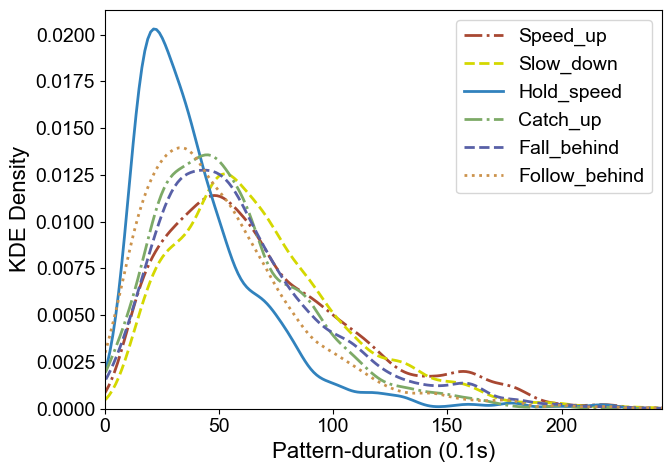

In [ ]:
# Three-three
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

plt.rc('font', family='Arial', size=16)  # Change 'Arial' to your preferred font and adjust the size

global_pattern_colors = {
    "speed_up": "#A84832",      # Darker red-orange, speed_up
    "slow_down": "#D4D800",     # Darker yellow-green, slow_down
    "hold_speed": "#3182BD",  # Darker cyan-blue, hold_speed
    "catch_up": "#7DAA67",    # Darker green, catch_up
    "fall_behind": "#5860A7",      # Darker blue-purple, fall_behind
    "follow_behind": "#CC934C"   # Darker yellow-brown, follow_behind
}

# Function to merge adjacent segments with the same pattern
def merge_same_pattern_segments(points, labels):
    merged_points = []
    merged_labels = []
    
    current_start = points[0]
    current_label = labels[0]

    for i in range(1, len(labels)):
        if labels[i] == current_label:  # Same pattern, continue merging
            continue
        else:
            # When the label changes, close the previous range and start a new one
            merged_points.append((current_start, points[i]))  # End at the last frame of the previous segment
            merged_labels.append(current_label)
            current_start = points[i]  # Start new range
            current_label = labels[i]  # Change to new pattern

    # Add the final pattern
    merged_points.append((current_start, points[-1]))
    merged_labels.append(current_label)

    return merged_points, merged_labels

# Function to calculate pattern durations for all selected vehicles
def calculate_pattern_durations(vehicle_indices):
    pattern_durations = {pattern: [] for pattern in global_pattern_colors.keys()}  # Initialize durations dictionary

    for vehicle_id_index in vehicle_indices:
        vehicle_id = labeled_data.loc[vehicle_id_index, 'VehicleID']
        vehicle_data = full_data[full_data['VehicleID'] == vehicle_id]

        # Extract the points and labels for the patterns
        pattern_points = eval(labeled_data.loc[vehicle_id_index, 'Point'])  # Convert string representation of list to actual list
        pattern_labels = eval(labeled_data.loc[vehicle_id_index, 'Label'])  # Convert string representation of list to actual list

        # Merge adjacent segments with the same pattern
        merged_points, merged_labels = merge_same_pattern_segments(pattern_points, pattern_labels)

        # Loop through each merged pattern segment and calculate the duration
        for i in range(len(merged_labels)):
            start_frame, end_frame = merged_points[i]
            duration = end_frame - start_frame
            if duration > 0:  # Only consider valid durations
                pattern_durations[merged_labels[i].lower()].append(duration)

    return pattern_durations

# Function to find the global maximum duration for setting xlim
def calculate_global_max_duration(pattern_durations):
    max_duration = 0
    for pattern, durations in pattern_durations.items():
        if durations:
            max_duration = max(max_duration, max(durations))
    return max_duration

import seaborn as sns

def plot_combined_pattern_durations_kde(vehicle_indices, save_path=None):
    # Calculate pattern durations
    pattern_durations = calculate_pattern_durations(vehicle_indices)

    # Find the global maximum duration across all patterns to set a shared xlim
    max_duration = calculate_global_max_duration(pattern_durations)

    fig, ax = plt.subplots(figsize=(7, 5))  # Create a single plot

    # Define all patterns and their line styles
    patterns = [
        ("speed_up", '-.'),
        ("slow_down", '--'),
        ("hold_speed", '-'),
        ("catch_up", '-.'),
        ("fall_behind", '--'),
        ("follow_behind", ':')
    ]

    # Plot KDE for each pattern
    for pattern, linestyle in patterns:
        durations = pattern_durations[pattern]
        if durations:  # Only plot if there are durations available
            color = global_pattern_colors.get(pattern.lower(), "black")
            sns.kdeplot(
                durations,
                bw_adjust=0.8,  # Adjust the bandwidth for KDE
                ax=ax,
                color=color,
                linestyle=linestyle,
                linewidth=2,
                label=pattern.capitalize()
            )

    # Set shared xlim for all patterns
    ax.set_xlim([0, max_duration + 5])  # Add some padding to the right

    # Set axis labels and titles
    ax.set_xlabel('Pattern-duration (0.1s)', fontsize=16, fontfamily='Arial')
    ax.set_ylabel('KDE Density', fontsize=16, fontfamily='Arial')
    # ax.set_title('KDE of Pattern Durations', fontsize=16, fontfamily='Arial')

    # Customize ticks
    ax.tick_params(axis='both', which='major', labelsize=14)

    # Add a legen
    ax.legend(loc='upper right', fontsize=14)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, format='pdf')

    # Show the plot
    plt.show()

# Example: Plot the combined histogram of pattern durations for vehicles in range 1600 to 2100tHE 
plot_combined_pattern_durations_kde(range(1, 2999), save_path=f"pattern_duration_KDE.pdf") # Change the range as needed
